### Machine Failure Prediction Classification 

#### Objective

The goal of this project is to predict machine failures based on sensor readings and operational settings.
Predicting potential failures in advance helps reduce maintenance costs, downtime, and improves overall production efficiency.


In [1]:
import pandas as pd
path = r"C:\Users\Sakshi\Downloads\train.cvs\train.csv"
df = pd.read_csv(path)
df.head()

,id,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,0,L50096,L,300.6,309.6,1596,36.1,140,0,0,0,0,0,0
1,1,M20343,M,302.6,312.1,1759,29.1,200,0,0,0,0,0,0
2,2,L49454,L,299.3,308.5,1805,26.5,25,0,0,0,0,0,0
3,3,L53355,L,301.0,310.9,1524,44.3,197,0,0,0,0,0,0
4,4,M24050,M,298.0,309.0,1641,35.4,34,0,0,0,0,0,0


In [2]:
len(df)

136429

In [3]:
df.shape

(136429, 14)

In [4]:
df.columns

Index(['id', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='str')

In [5]:
df.value_counts()

id      Product ID  Type  Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  TWF  HDF  PWF  OSF  RNF
0       L50096      L     300.6                309.6                    1596                    36.1         140              0                0    0    0    0    0      1
1       M20343      M     302.6                312.1                    1759                    29.1         200              0                0    0    0    0    0      1
2       L49454      L     299.3                308.5                    1805                    26.5         25               0                0    0    0    0    0      1
3       L53355      L     301.0                310.9                    1524                    44.3         197              0                0    0    0    0    0      1
4       M24050      M     298.0                309.0                    1641                    35.4         34               0                0 

In [6]:
cols = ["Machine failure", "TWF", "HDF", "PWF", "OSF", "RNF"]

print(df[cols].sum())

Machine failure    2148
TWF                 212
HDF                 704
PWF                 327
OSF                 540
RNF                 308
dtype: int64


In [7]:
df["Machine failure"].value_counts()

Machine failure
0    134281
1      2148
Name: count, dtype: int64

**Analysis**

- Class 0 (No Failure) has 134,281 records.
- Class 1 (Failure) has 2,148 records.
- The dataset is highly imbalanced, as most records belong to Class 0

### Data Cleaning 

In [8]:
# Checking missing Value
df.isnull().sum()

id                         0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [9]:
# Check Duplicate Row
df.duplicated().sum()

np.int64(0)

In [10]:
# Check Data types

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 136429 entries, 0 to 136428
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       136429 non-null  int64  
 1   Product ID               136429 non-null  str    
 2   Type                     136429 non-null  str    
 3   Air temperature [K]      136429 non-null  float64
 4   Process temperature [K]  136429 non-null  float64
 5   Rotational speed [rpm]   136429 non-null  int64  
 6   Torque [Nm]              136429 non-null  float64
 7   Tool wear [min]          136429 non-null  int64  
 8   Machine failure          136429 non-null  int64  
 9   TWF                      136429 non-null  int64  
 10  HDF                      136429 non-null  int64  
 11  PWF                      136429 non-null  int64  
 12  OSF                      136429 non-null  int64  
 13  RNF                      136429 non-null  int64  
dtypes: float64(3), 

In [11]:
df.nunique()

id                         136429
Product ID                   9976
Type                            3
Air temperature [K]            95
Process temperature [K]        81
Rotational speed [rpm]        952
Torque [Nm]                   611
Tool wear [min]               246
Machine failure                 2
TWF                             2
HDF                             2
PWF                             2
OSF                             2
RNF                             2
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

### Observation 
- Total records: 136,429
- Total columns: 14
- Missing values: 0
- Duplicate rows: 0
- Data types: Checked
- Target variable: Machine failure contains both 0 and 1.
- Class distribution: Highly imbalanced.

### Exploratory Data Analysis(EDA)

In [13]:
# Statistical Summary
df.describe()

,id,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000
mean,68214.000000,299.862776,309.941070,1520.331110,40.348643,104.408901,0.015744,0.001554,0.005160,0.002397,0.003958,0.002258
std,39383.804275,1.862247,1.385173,138.736632,8.502229,63.965040,0.124486,0.039389,0.071649,0.048899,0.062789,0.047461
min,0.000000,295.300000,305.800000,1181.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,34107.000000,298.300000,308.700000,1432.000000,34.600000,48.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,68214.000000,300.000000,310.000000,1493.000000,40.400000,106.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,102321.000000,301.200000,310.900000,1580.000000,46.100000,159.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,136428.000000,304.400000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## Observation 

- Air temperature: The average surrounding air temperature is about 300 K.
- Process temperature: The average machine process temperature is about 310 K.
- Rotational speed: The machine rotates at an average speed of 1,520 rpm.
- Torque: The average rotational force is 40.35 Nm.
- Tool wear: The average tool usage is about 104 minutes.
- Failure indicators: These columns contain 0 (failure type not detected) or 1 (failure type detected).

- Dataset completeness: No missing values were found in the numerical columns.

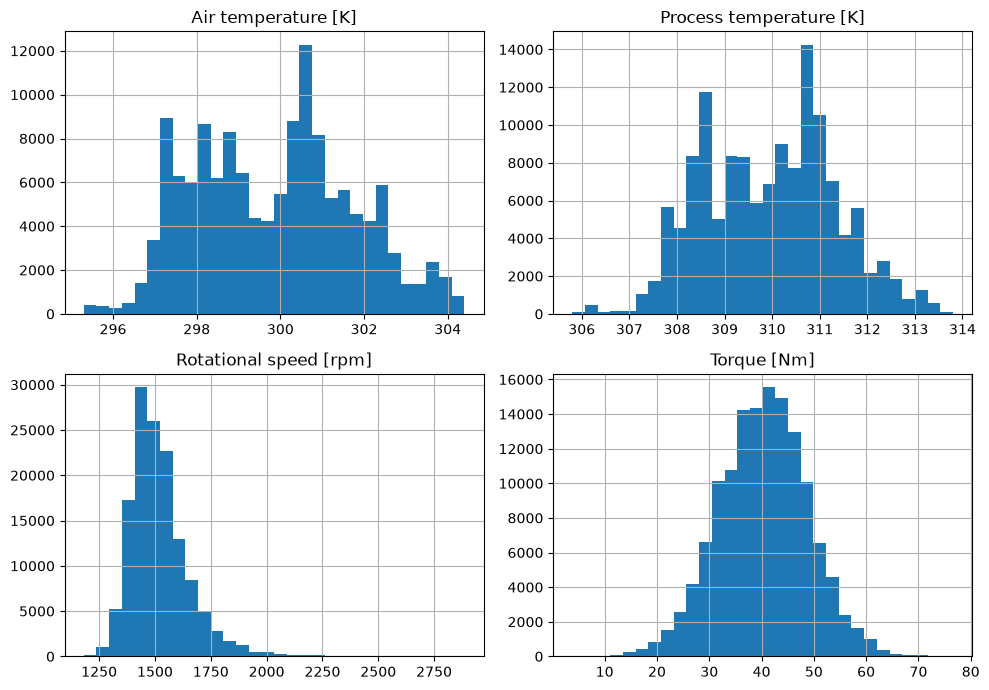

In [14]:
# Histogram
import matplotlib.pyplot as plt

cols = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]"
]

df[cols].hist(figsize=(10, 7), bins=30)
plt.tight_layout()
plt.show()

### Observation

1. Air Temperature: Multiple peaks; most values lie between 297–303 K. No obvious extreme outliers.

2. Process Temperature: Multiple peaks; most values lie between 308–312 K. No obvious extreme outliers.

3. Rotational Speed: Right-skewed; most values lie between 1,350–1,700 rpm. Potential high-value outliers are present.

4. Torque: Approximately normally distributed; most values lie between 30–50 Nm. Some extreme values may be present.

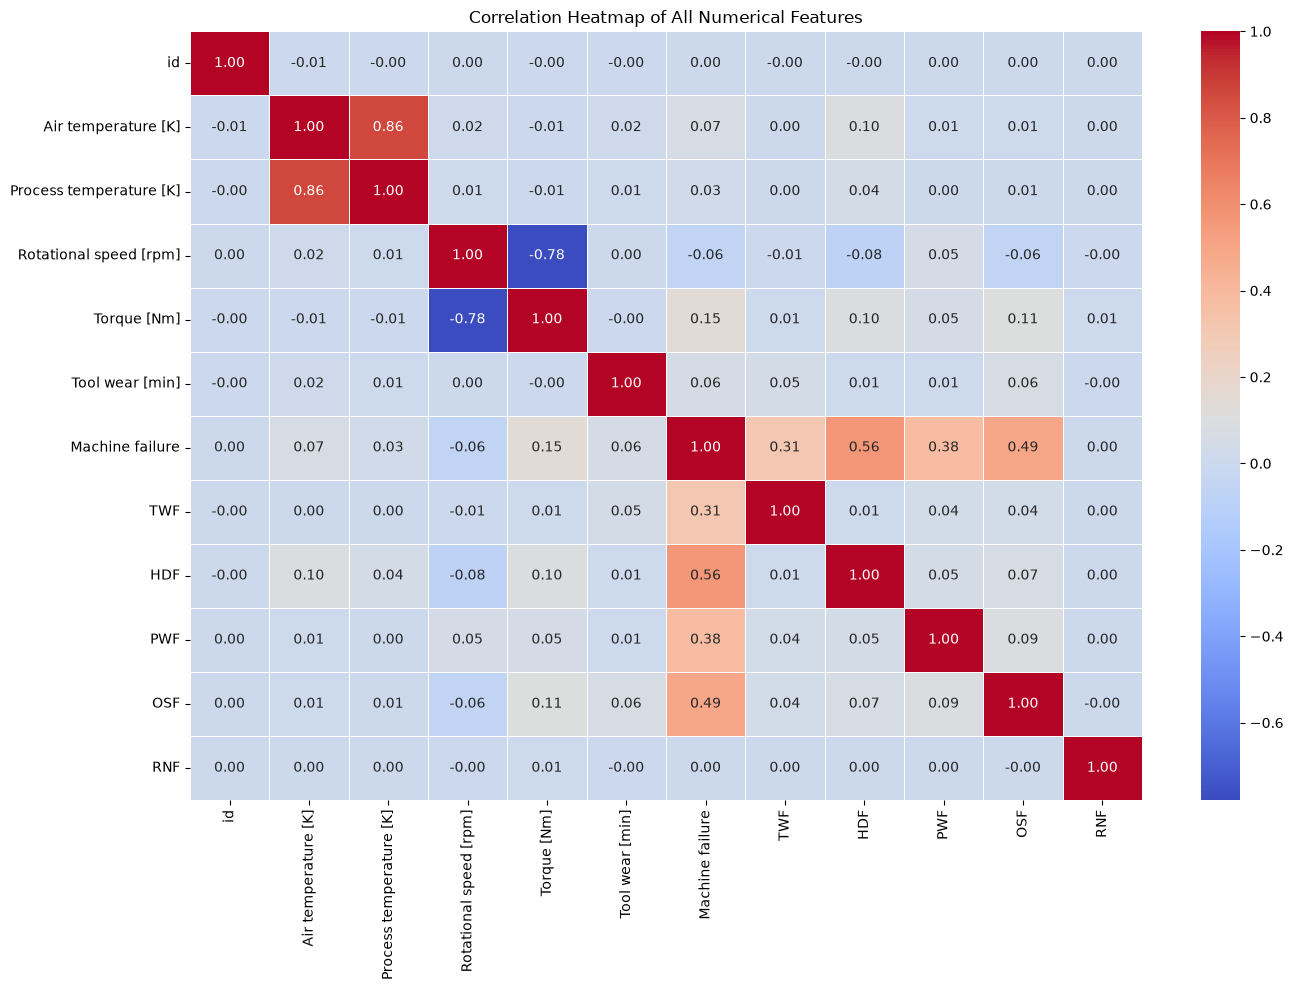

In [15]:
# Correlation 
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 10))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of All Numerical Features")
plt.tight_layout()
plt.show()


### Obesrvation 
1. Air Temperature and Process Temperature: Strong positive correlation (0.86).

2. Rotational Speed and Torque: Strong negative correlation (-0.78).
3. Machine Failure and HDF: Moderate positive correlation (0.56).
4. Machine Failure and OSF: Moderate positive correlation (0.49).
5. Machine Failure and PWF: Weak positive correlation (0.38).
Other features: Show weak or almost no correlation.

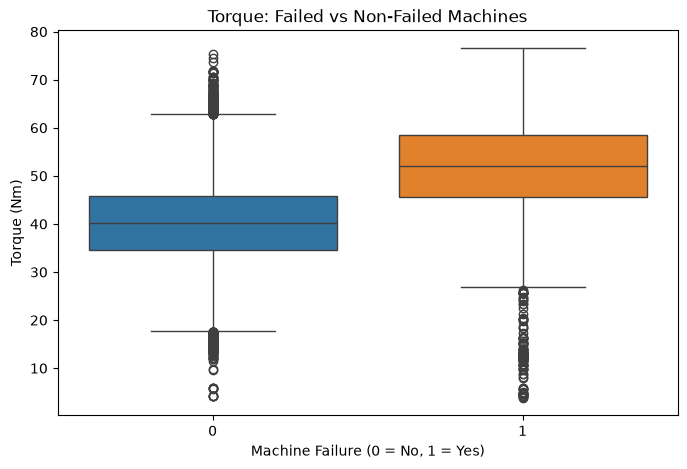

In [16]:
# Box plot
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Machine failure",
    y="Torque [Nm]",
    hue="Machine failure",
    legend=False
)

plt.title("Torque: Failed vs Non-Failed Machines")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Torque (Nm)")
plt.show()

### Observation 

1. Median: Failed machines (1) have higher median torque (52 Nm) than non-failed machines (0) (40 Nm).
2. Spread: Failed machines show a wider range of torque values.
3. Outliers: Both groups contain outliers.

In [17]:
con = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

In [18]:
# Outlier Handling Using IQR Method

df_clean = df.copy()

for col in con:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    df_clean = df_clean[
        (df_clean[col] >= lower) &
        (df_clean[col] <= upper)
    ]

print("Original shape:", df.shape)
print("Shape after removing outliers:", df_clean.shape)
print("Total rows removed:", len(df) - len(df_clean))

Original shape: (136429, 14)
Shape after removing outliers: (130618, 14)
Total rows removed: 5811


### Observation
1. The original dataset contained 136,429 rows and 14 columns.
2. The IQR method removed 5,811 rows containing outliers.
3. After outlier removal, the dataset contained 130,618 rows and 14 columns.
4. Approximately 4.26% of the rows were removed.

In [19]:
print(df_clean.columns.tolist())

['id', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


### Separate X and Y Features 

In [20]:
X = df_clean.drop(
    columns=["Machine failure", "id", "Product ID", "TWF", "HDF", "PWF", "OSF", "RNF"]
)

y = df_clean["Machine failure"]

print("X shape:", X.shape)
print("y shape:", y.shape)
display(X.head())
display(y.head())

X shape: (130618, 6)
y shape: (130618,)


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,L,300.6,309.6,1596,36.1,140
1,M,302.6,312.1,1759,29.1,200
3,L,301.0,310.9,1524,44.3,197
4,M,298.0,309.0,1641,35.4,34
5,M,298.4,308.9,1429,42.1,65


0    0
1    0
3    0
4    0
5    0
Name: Machine failure, dtype: int64

#### By Observing y data is Imbalanced

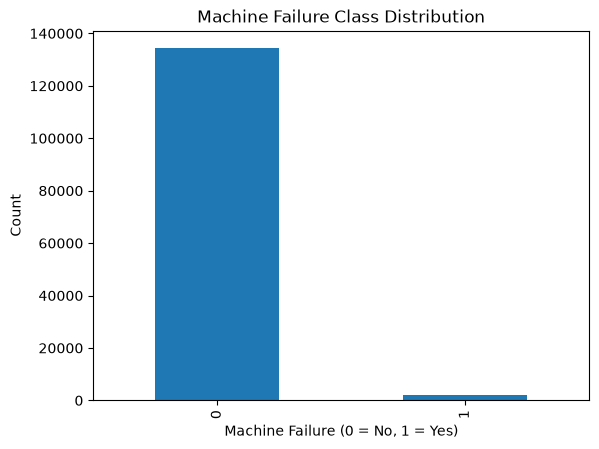

In [21]:
import matplotlib.pyplot as plt

df["Machine failure"].value_counts().sort_index().plot(kind="bar")

plt.title("Machine Failure Class Distribution")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()

**Analysis**

- Class 0 (No Failure) has 134,281 records.
- Class 1 (Failure) has 2,148 records.
- The dataset is highly imbalanced, as most records belong to Class 0

### Feature Engineering

In [22]:
X["Temperature Difference"] = (
    X["Process temperature [K]"] -
    X["Air temperature [K]"]
)

print(X.head())

  Type  Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
0    L                300.6                    309.6                    1596   
1    M                302.6                    312.1                    1759   
3    L                301.0                    310.9                    1524   
4    M                298.0                    309.0                    1641   
5    M                298.4                    308.9                    1429   

   Torque [Nm]  Tool wear [min]  Temperature Difference  
0         36.1              140                     9.0  
1         29.1              200                     9.5  
3         44.3              197                     9.9  
4         35.4               34                    11.0  
5         42.1               65                    10.5  


In [23]:
cat_onehot = []
cat_label = ["Type"]

con = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

In [24]:

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder,LabelEncoder
from sklearn.compose import ColumnTransformer

num_pipe = make_pipeline(SimpleImputer(strategy='median'),
                         StandardScaler())

cat_pipe = make_pipeline(SimpleImputer(strategy='most_frequent'),
                         OneHotEncoder(handle_unknown='ignore',sparse_output=False))

pre = ColumnTransformer([('cat',cat_pipe,cat_onehot),
                         ('con',num_pipe,con)]).set_output(transform='pandas')

from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest = train_test_split(X,y,random_state=21,train_size=0.75)

pre.fit(xtrain)

xtrain_pre = pre.transform(xtrain)
xtest_pre = pre.transform(xtest)

# Apply LabelEncoder separately
encoders = {}

for col in cat_label:
    # Impute missing values using training data's most frequent value
    most_frequent = xtrain[col].mode().iloc[0]

    train_col = xtrain[col].fillna(most_frequent).astype(str)
    test_col = xtest[col].fillna(most_frequent).astype(str)

    le = LabelEncoder()
    xtrain_pre[col] = le.fit_transform(train_col)

    # Handle categories in test data that weren't present in training
    mapping = {v: i for i, v in enumerate(le.classes_)}
    xtest_pre[col] = test_col.map(mapping).fillna(-1).astype(int)

    encoders[col] = le

In [25]:
xtrain_pre.columns

Index(['con__Air temperature [K]', 'con__Process temperature [K]',
       'con__Rotational speed [rpm]', 'con__Torque [Nm]',
       'con__Tool wear [min]', 'Type'],
      dtype='str')

In [26]:

xtrain_pre = pre.transform(xtrain)
xtest_pre = pre.transform(xtest)

### Step: Handling Imbalanced Data Using Oversampling(Resampling)

    The target variable Machine failure is highly imbalanced, with significantly more non-failure cases than failure cases. This imbalance may cause the model to favor the majority class.


In [27]:
len(xtrain_pre)

97963

In [28]:
ytrain.value_counts()

Machine failure
0    96692
1     1271
Name: count, dtype: int64

In [29]:
from imblearn.over_sampling import SMOTE, ADASYN

smote = SMOTE(random_state=42)

x_sampl, y_sampl = smote.fit_resample(
    xtrain_pre, ytrain
)

In [30]:
len(y_sampl)

193384

In [31]:
y_sampl.value_counts()

Machine failure
0    96692
1    96692
Name: count, dtype: int64

In [32]:

import re
# Replace [, ], and < with an underscore
xtrain_pre.columns = [re.sub(r'[\[\]<]', '_', str(col)) for col in xtrain_pre.columns]
xtest_pre.columns = [re.sub(r'[\[\]<]', '_', str(col)) for col in xtest_pre.columns]

In [36]:
import re

def clean_columns(data):
    data.columns = [
        re.sub(r'[\[\]<]', '_', str(col))
        for col in data.columns
    ]
    return data

x_sampl = clean_columns(x_sampl)
xtest_pre = clean_columns(xtest_pre)

# Check feature names
print("Training columns:", x_sampl.columns.tolist())
print("Testing columns:", xtest_pre.columns.tolist())

print("Columns match:", 
      x_sampl.columns.tolist() == xtest_pre.columns.tolist())

Training columns: ['con__Air temperature _K_', 'con__Process temperature _K_', 'con__Rotational speed _rpm_', 'con__Torque _Nm_', 'con__Tool wear _min_']
Testing columns: ['con__Air temperature _K_', 'con__Process temperature _K_', 'con__Rotational speed _rpm_', 'con__Torque _Nm_', 'con__Tool wear _min_']
Columns match: True


### Model Building

### Algorithm Evaluation

In [37]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

In [38]:
dct = {
    "Logistic": LogisticRegression(max_iter=2000),
    "DecisionTree": DecisionTreeClassifier(random_state=42),
    "RandomForest": RandomForestClassifier(
        random_state=42, n_jobs=-1
    ),
    "GradientBoosting": GradientBoostingClassifier(
        random_state=42
    ),
    "XGBoost": XGBClassifier(
        random_state=42, eval_metric="logloss"
    ),
   
}


In [39]:
roc_scores = []

for name, model in dct.items():

    # Fit the model on SMOTE training data
    model.fit(x_sampl, y_sampl)

    # Predict scores on the original test data
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(xtest_pre)[:, 1]
    else:
        y_score = model.decision_function(xtest_pre)

    # Calculate ROC-AUC
    auc = roc_auc_score(ytest, y_score)
    roc_scores.append(round(auc, 3))

    print(name, "ROC-Score:", round(auc, 3))

print("ROC-Score:", roc_scores)

Logistic ROC-Score: 0.859
DecisionTree ROC-Score: 0.655
RandomForest ROC-Score: 0.877
GradientBoosting ROC-Score: 0.907
XGBoost ROC-Score: 0.887
ROC-Score: [0.859, 0.655, 0.877, 0.907, 0.887]


In [40]:
res = {
    'Name': list(dct.keys()),
    'ROC_Score': roc_scores
}

df_res = pd.DataFrame(res)

df_res.sort_values(by='ROC_Score', ascending=False)

,Name,ROC_Score
3,GradientBoosting,0.907
4,XGBoost,0.887
2,RandomForest,0.877
0,Logistic,0.859
1,DecisionTree,0.655


### Gradient Boosting has the highest ROC-AUC score (0.907) we  consider this model for final deployment

### HyperParameter Tunning

In [41]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import roc_auc_score
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [42]:
## Create Model 
gb = GradientBoostingClassifier(random_state=42)

In [43]:
# Hyperparameters
param_grid = {
    "model__n_estimators": [100, 150, 200],
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__max_depth": [2, 3, 5],
    "model__subsample": [0.8, 1.0]
}

In [44]:
# Create Pipeline
pipe = Pipeline([
    ("smote", SMOTE(random_state=42)), # helps to prevent information leakage between Folds
    ("model", gb)
])

In [45]:
# Configure Hyperparameters tunning
random_search = RandomizedSearchCV(
    estimator=pipe,
    param_distributions=param_grid,
    n_iter=10,
    scoring="roc_auc",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [46]:
random_search.fit(xtrain_pre, ytrain)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__learning_rate': [0.01, 0.05, ...], 'model__max_depth': [2, 3, ...], 'model__n_estimators': [100, 150, ...], 'model__subsample': [0.8, 1.0]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a 

In [47]:
gb = random_search.best_estimator_


In [48]:
print(random_search.best_params_)

{'model__subsample': 0.8, 'model__n_estimators': 150, 'model__max_depth': 3, 'model__learning_rate': 0.1}


In [49]:
print(random_search.best_score_)

0.921283933187929


In [50]:
y_pred = gb.predict(xtest_pre)

In [51]:
y_score = gb.predict_proba(xtest_pre)[:, 1]

### Evalution metrics 
 

In [52]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Accuracy:", accuracy_score(ytest, y_pred))
print("Precision:", precision_score(ytest, y_pred, zero_division=0))
print("Recall:", recall_score(ytest, y_pred, zero_division=0))
print("F1-score:", f1_score(ytest, y_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(ytest, y_score))

print("\nClassification Report:")
print(classification_report(ytest, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(ytest, y_pred))


Accuracy: 0.8566452304394426
Precision: 0.07528764382191096
Recall: 0.8624641833810889
F1-score: 0.13848631239935588
ROC-AUC: 0.9219552608394777

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.86      0.92     25775
           1       0.08      0.86      0.14       349

    accuracy                           0.86     26124
   macro avg       0.54      0.86      0.53     26124
weighted avg       0.99      0.86      0.91     26124


Confusion Matrix:
[[22078  3697]
 [   48   301]]


#### Confusion metrics


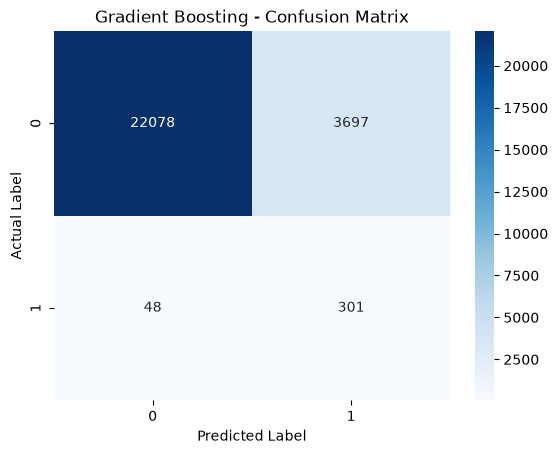

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(ytest, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Gradient Boosting - Confusion Matrix")
plt.show()

#### Roc Curve 

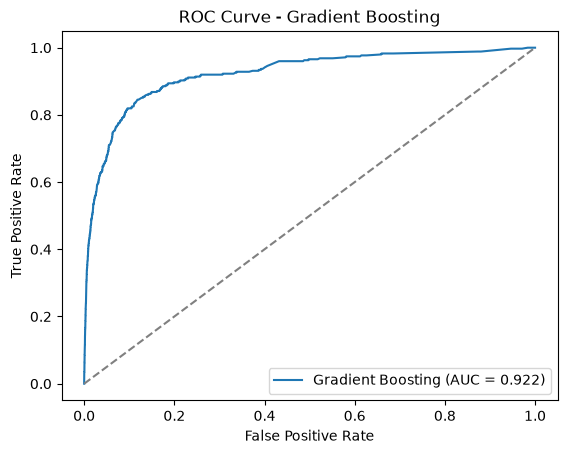

In [54]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(ytest, y_score)
auc = roc_auc_score(ytest, y_score)

plt.plot(fpr, tpr, label=f"Gradient Boosting (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Gradient Boosting")
plt.legend()
plt.show()

In [55]:
print("Best CV ROC-AUC:", random_search.best_score_)
print("Best Parameters:", random_search.best_params_)

Best CV ROC-AUC: 0.911634218330267
Best Parameters: {'model__subsample': 1.0, 'model__n_estimators': 100, 'model__max_depth': 2, 'model__learning_rate': 0.05}


### Save the finalized model and Pipeline

In [56]:
import joblib
# Save Model
joblib.dump(gb, "gradient_boosting_model.pkl")
# Save preproccing Pipeline
joblib.dump(pre, "preprocessing_pipeline.pkl")

['preprocessing_pipeline.pkl']

### Data Gathering form test.csv 

In [57]:
test = pd.read_csv(r"C:\Users\Sakshi\Downloads\test.csv")
test.head()


,id,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],TWF,HDF,PWF,OSF,RNF
0,136429,L50896,L,302.3,311.5,1499,38.0,60,0,0,0,0,0
1,136430,L53866,L,301.7,311.0,1713,28.8,17,0,0,0,0,0
2,136431,L50498,L,301.3,310.4,1525,37.7,96,0,0,0,0,0
3,136432,M21232,M,300.1,309.6,1479,47.6,5,0,0,0,0,0
4,136433,M19751,M,303.4,312.3,1515,41.3,114,0,0,0,0,0


In [58]:
# Same Six Features used during Training
xnew = test[
    [
        "Type",
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]"
    ]
]

In [59]:
# Transform using your fitted preproccing pipeline
xnew_pre = pre.transform(xnew)
xnew_pre

array([[ 0.        ,  1.        ,  0.        , ..., -0.04877523,
        -0.37791785, -0.69528042],
       [ 0.        ,  1.        ,  0.        , ...,  1.99114029,
        -1.57482228, -1.3690052 ],
       [ 0.        ,  1.        ,  0.        , ...,  0.19906497,
        -0.41694734, -0.13123176],
       ...,
       [ 0.        ,  1.        ,  0.        , ..., -0.0297106 ,
         0.06441639,  1.2945579 ],
       [ 0.        ,  1.        ,  0.        , ...,  0.28485581,
        -0.07869175, -0.55426825],
       [ 0.        ,  1.        ,  0.        , ...,  0.28485581,
        -0.62510464, -0.19390383]], shape=(90954, 8))

In [60]:
gb = random_search.best_estimator_

In [61]:
xnew_pre = pre.transform(xnew)

In [62]:
predictions = gb.predict(xnew_pre)

predictions

array([0, 0, 0, ..., 0, 0, 0], shape=(90954,))

In [63]:

xnew['machine failure'] = predictions
xnew

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],machine failure
0,L,302.3,311.5,1499,38.0,60,0
1,L,301.7,311.0,1713,28.8,17,0
2,L,301.3,310.4,1525,37.7,96,0
3,M,300.1,309.6,1479,47.6,5,0
4,M,303.4,312.3,1515,41.3,114,0
...,...,...,...,...,...,...,...
90949,L,302.3,311.4,1484,40.4,15,0
90950,L,297.9,309.8,1542,33.8,31,0
90951,L,295.6,306.2,1501,41.4,187,0
90952,L,298.1,307.8,1534,40.3,69,0


In [64]:
y_score = gb.predict_proba(xnew_pre)[:, 1]

print(y_score.min())
print(y_score.max())
print(y_score.mean())

0.05779682834123503
0.9795264178426499
0.24578136876462148


In [65]:
import numpy as np

predictions_05 = (y_score >= 0.5).astype(int)

print("Prediction counts:")
print(np.unique(predictions_05, return_counts=True))

Prediction counts:
(array([0, 1]), array([77335, 13619]))


In [66]:
# Save the Final Prediction file

test["Predicted Machine Failure"] = predictions_05

test.to_csv("machine_failure_predictions.csv", index=False)

### Insights & Conclusions

## Insights & Conclusions

### Key Insights

1. **Class Imbalance:** The original dataset contained 136,429 records, including 2,148 machine failure cases and 134,281 non-failure cases. The dataset was highly imbalanced.

2. **Data Cleaning:** The IQR method removed 5,811 rows, reducing the dataset to 130,618 records. Some genuine failure cases may also have been removed during outlier handling.

3. **Feature Selection:** Six features were selected for prediction: Type, Air Temperature, Process Temperature, Rotational Speed, Torque, and Tool Wear.

4. **Data Preprocessing:** Numerical features were standardized, and the categorical Type feature was label encoded. SMOTE was applied to balance the training data.

5. **Model Comparison:** Five classification algorithms were evaluated. Gradient Boosting achieved the highest ROC-AUC score of 0.907, followed by XGBoost (0.887), Random Forest (0.877), Logistic Regression (0.859), and Decision Tree (0.655).

6. **Hyperparameter Tuning:** RandomizedSearchCV was used to tune the Gradient Boosting model with 10 parameter combinations and 3-fold cross-validation. The reported best cross-validation ROC-AUC score was 0.9213.

7. **Final Model Evaluation:** The tuned Gradient Boosting model achieved 85.66% accuracy, 7.53% precision, 86.25% recall, an F1-score of 13.85%, and a ROC-AUC score of 0.922 on the evaluation dataset.

8. **Confusion Matrix:** The model correctly identified 301 actual failure cases and 22,078 non-failure cases. It missed 48 actual failures and incorrectly flagged 3,697 non-failure cases as failures.

9. **Prediction on Unseen Data:** The final model was applied to 90,954 records from the separate test dataset. Using a 0.5 probability threshold, 13,619 records were predicted as potential failures and 77,335 as non-failures.

### Conclusion

The Machine Failure Prediction project demonstrates how machine learning can be used to predict potential machine failures based on sensor readings and operational data. After data cleaning, exploratory data analysis, feature selection, preprocessing, and class balancing using SMOTE, five classification algorithms were compared. Gradient Boosting was selected because it achieved the highest ROC-AUC score during model comparison.

Hyperparameter tuning further improved the model's performance, achieving a ROC-AUC score of approximately 0.922 on the held-out evaluation dataset. The model identified 86.25% of actual failure cases, but its precision was only 7.53%, indicating a high number of false alarms.

Finally, the model generated predictions for 90,954 unseen records, identifying 13,619 as potential machine failures. These predictions could help prioritize machine inspections and support preventive maintenance planning. Further improvements are needed to reduce false alarms and select an appropriate classification threshold before the model can be reliably used in a real manufacturing environment.